In [1]:
from google.colab import files
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training on: {device.type.upper()}")
if device.type == 'cpu':
    raise SystemError("Switch to GPU in Runtime > Change runtime type")

uploaded = files.upload()

Training on: CUDA


Saving tinystories_small.txt to tinystories_small.txt


In [2]:
file_name = list(uploaded.keys())[0]
text_data = uploaded[file_name].decode("utf-8").lower()

tokens = text_data.split()
vocab = ["<pad>"] + list(sorted(set(tokens)))
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for i, w in enumerate(vocab)}
vocab_size = len(vocab)

all_indices = [word2idx[w] for w in tokens if w in word2idx]

WINDOW_SIZE = 30
input_seqs = []

for i in range(1, len(all_indices)):
    start_idx = max(0, i - WINDOW_SIZE)
    seq = all_indices[start_idx:i+1]
    input_seqs.append(seq)

max_seq_len = min(WINDOW_SIZE + 1, max(len(s) for s in input_seqs))
padded_seqs = np.zeros((len(input_seqs), max_seq_len), dtype=np.int64)

for i, s in enumerate(input_seqs):
    padded_seqs[i, -len(s):] = s

X = padded_seqs[:, :-1]
y = padded_seqs[:, -1]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = torch.tensor(X_train, dtype=torch.long)
y_train = torch.tensor(y_train, dtype=torch.long)
X_val = torch.tensor(X_val, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)

class TextDataset(Dataset):
    def __init__(self, X_data, y_data):
        self.X_data = X_data
        self.y_data = y_data
    def __len__(self):
        return len(self.X_data)
    def __getitem__(self, idx):
        return self.X_data[idx], self.y_data[idx]

train_loader = DataLoader(TextDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TextDataset(X_val, y_val), batch_size=128, shuffle=False)

print(f"Total Sequences: {len(input_seqs)}")
print(f"Max Sequence Length constraint applied: {max_seq_len}")

Total Sequences: 1690707
Max Sequence Length constraint applied: 31


In [3]:
class AutoregressiveModel(nn.Module):
    def __init__(self, arch_type, v_size, embed_dim=128, hidden_dim=256):
        super().__init__()
        self.embedding = nn.Embedding(v_size, embed_dim, padding_idx=0)

        if arch_type == 'RNN':
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
            fc_in = hidden_dim
        elif arch_type == 'BiRNN':
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
            fc_in = hidden_dim * 2
        elif arch_type == 'LSTM':
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
            fc_in = hidden_dim
        elif arch_type == 'GRU':
            self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
            fc_in = hidden_dim

        self.fc = nn.Linear(fc_in, v_size)

    def forward(self, x):
        embeds = self.embedding(x)
        out, _ = self.rnn(embeds)
        return self.fc(out[:, -1, :])

model_dict = {
    "RNN": AutoregressiveModel('RNN', vocab_size).to(device),
    "BiRNN": AutoregressiveModel('BiRNN', vocab_size).to(device),
    "LSTM": AutoregressiveModel('LSTM', vocab_size).to(device),
    "GRU": AutoregressiveModel('GRU', vocab_size).to(device)
}

histories = {m: {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []} for m in model_dict}
training_times = {}
best_val_metrics = {}

for m_name, model in model_dict.items():
    print(f"\n--- Training {m_name} ---")
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    best_val_loss = float('inf')
    patience = 7
    patience_counter = 0
    best_weights = None

    start_t = time.time()

    for epoch in range(50):
        model.train()
        t_loss, t_correct, t_total = 0.0, 0, 0

        for b_x, b_y in train_loader:
            b_x, b_y = b_x.to(device), b_y.to(device)
            optimizer.zero_grad()
            out = model(b_x)
            loss = criterion(out, b_y)
            loss.backward()
            optimizer.step()

            t_loss += loss.item() * b_x.size(0)
            t_correct += (out.argmax(1) == b_y).sum().item()
            t_total += b_y.size(0)

        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for b_x, b_y in val_loader:
                b_x, b_y = b_x.to(device), b_y.to(device)
                out = model(b_x)
                loss = criterion(out, b_y)

                v_loss += loss.item() * b_x.size(0)
                v_correct += (out.argmax(1) == b_y).sum().item()
                v_total += b_y.size(0)

        e_t_loss = t_loss / t_total
        e_t_acc = t_correct / t_total
        e_v_loss = v_loss / v_total
        e_v_acc = v_correct / v_total

        histories[m_name]['train_loss'].append(e_t_loss)
        histories[m_name]['val_loss'].append(e_v_loss)
        histories[m_name]['train_acc'].append(e_t_acc)
        histories[m_name]['val_acc'].append(e_v_acc)

        print(f"Epoch {epoch+1:02d}/50 | Train Loss: {e_t_loss:.4f} | Val Loss: {e_v_loss:.4f} | Early Stop Count: {patience_counter}/7")

        if e_v_loss < best_val_loss:
            best_val_loss = e_v_loss
            patience_counter = 0
            best_weights = model.state_dict().copy()
            best_val_metrics[m_name] = {'loss': e_v_loss, 'acc': e_v_acc}
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered for {m_name}")
                break

    if best_weights:
        model.load_state_dict(best_weights)

    training_times[m_name] = time.time() - start_t


--- Training RNN ---
Epoch 01/50 | Train Loss: 4.6285 | Val Loss: 4.2719 | Early Stop Count: 0/7
Epoch 02/50 | Train Loss: 3.9859 | Val Loss: 4.1673 | Early Stop Count: 0/7
Epoch 03/50 | Train Loss: 3.8349 | Val Loss: 4.1632 | Early Stop Count: 0/7
Epoch 04/50 | Train Loss: 3.7008 | Val Loss: 4.1809 | Early Stop Count: 0/7
Epoch 05/50 | Train Loss: 3.6353 | Val Loss: 4.1999 | Early Stop Count: 1/7
Epoch 06/50 | Train Loss: 3.6269 | Val Loss: 4.2542 | Early Stop Count: 2/7
Epoch 07/50 | Train Loss: 3.6633 | Val Loss: 4.2309 | Early Stop Count: 3/7
Epoch 08/50 | Train Loss: 3.6091 | Val Loss: 4.2474 | Early Stop Count: 4/7
Epoch 09/50 | Train Loss: 3.6033 | Val Loss: 4.2510 | Early Stop Count: 5/7
Epoch 10/50 | Train Loss: 3.6429 | Val Loss: 4.2862 | Early Stop Count: 6/7
Early stopping triggered for RNN

--- Training BiRNN ---
Epoch 01/50 | Train Loss: 4.7022 | Val Loss: 4.3342 | Early Stop Count: 0/7
Epoch 02/50 | Train Loss: 4.0581 | Val Loss: 4.2680 | Early Stop Count: 0/7
Epoch 03/

,Model,Train Time (s),Val Loss,Val Accuracy,Perplexity
0,RNN,1004.47,4.1632,0.2887,64.2748
1,BiRNN,1455.84,4.2680,0.2793,71.3792
2,LSTM,1242.55,3.7142,0.3405,41.0244
3,GRU,1194.54,3.7158,0.3365,41.0929


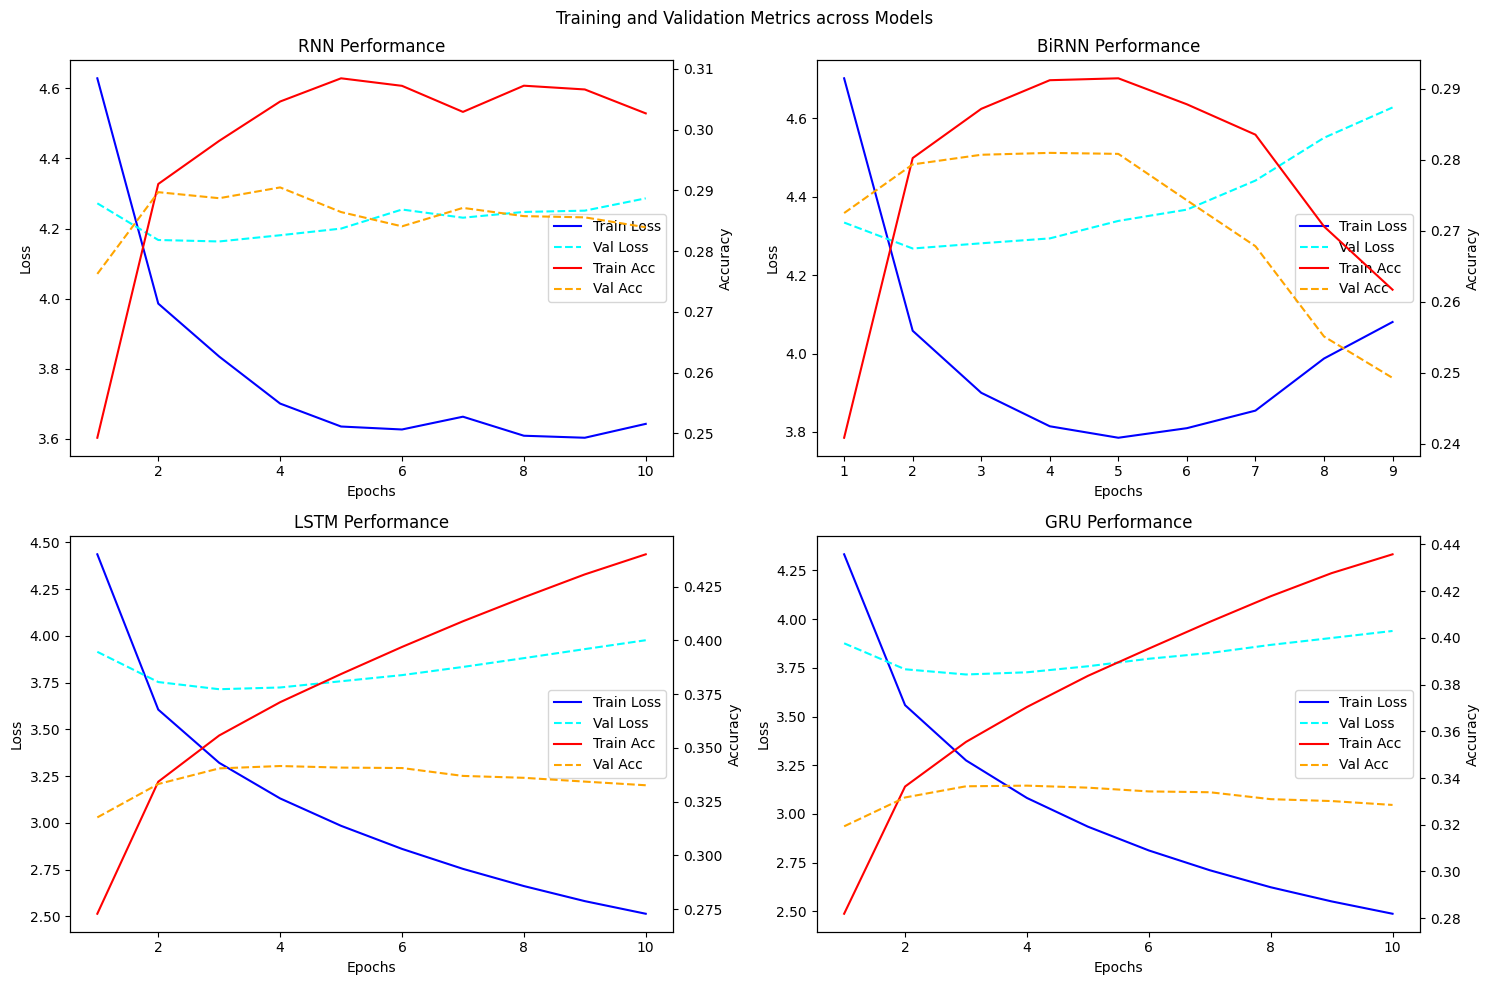

In [4]:
results = []
for m_name in model_dict.keys():
    v_loss = best_val_metrics[m_name]['loss']
    v_acc = best_val_metrics[m_name]['acc']

    results.append({
        "Model": m_name,
        "Train Time (s)": round(training_times[m_name], 2),
        "Val Loss": round(v_loss, 4),
        "Val Accuracy": round(v_acc, 4),
        "Perplexity": round(np.exp(v_loss), 4)
    })

metrics_df = pd.DataFrame(results)
display(metrics_df)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Training and Validation Metrics across Models')

for ax_idx, m_name in enumerate(model_dict.keys()):
    row = ax_idx // 2
    col = ax_idx % 2
    ax = axes[row, col]

    epochs_run = range(1, len(histories[m_name]['train_loss']) + 1)

    ax.plot(epochs_run, histories[m_name]['train_loss'], label='Train Loss', color='blue')
    ax.plot(epochs_run, histories[m_name]['val_loss'], label='Val Loss', color='cyan', linestyle='--')

    ax2 = ax.twinx()
    ax2.plot(epochs_run, histories[m_name]['train_acc'], label='Train Acc', color='red')
    ax2.plot(epochs_run, histories[m_name]['val_acc'], label='Val Acc', color='orange', linestyle='--')

    ax.set_title(f'{m_name} Performance')
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Loss')
    ax2.set_ylabel('Accuracy')

    lines_1, labels_1 = ax.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')

plt.tight_layout()
plt.show()

In [5]:
def apply_temperature(logits, temp):
    logits = logits / temp
    probs = torch.softmax(logits, dim=-1).cpu().numpy()
    return np.random.choice(len(probs), p=probs)

def generate_sequence(model, seed, n_words, temp):
    model.eval()
    words = seed.lower().split()

    with torch.no_grad():
        for _ in range(n_words):
            seq = [word2idx.get(w, 0) for w in words]
            padded = np.zeros((1, max_seq_len - 1), dtype=np.int64)
            padded[0, -len(seq):] = seq[-max_seq_len+1:]

            inp = torch.tensor(padded, dtype=torch.long).to(device)
            logits = model(inp)[0]
            next_idx = apply_temperature(logits, temp)
            words.append(idx2word.get(next_idx, ""))

    return " ".join(words)

seed_str = "once upon a time there was"
temp_scales = [0.2, 0.7, 1.2]

print(f"Base Seed: '{seed_str}'\n")

for m_name, model in model_dict.items():
    print(f"[{m_name} Generations]")
    for t in temp_scales:
        gen_out = generate_sequence(model, seed_str, 25, t)
        print(f"Temp {t}: {gen_out}")
    print("-" * 50)

Base Seed: 'once upon a time there was'

[RNN Generations]
Temp 0.2: once upon a time there was a little girl called lucy. she was three years old. she was three years old. she was three years old. she loved to play with
Temp 0.7: once upon a time there was a pilot. she wanted to choose another ball. he thanked her for playing with her family. so, the little girl was happy to have found
Temp 1.2: once upon a time there was the elephant "can i fill my and colorful place." yes. lucy turned out into the phone and stepped closer to animals they became cold. sarah
--------------------------------------------------
[BiRNN Generations]
Temp 0.2: once upon a time there was a little girl named lily. she loved to play with her toys and they had a great time. once upon a time, there was a
Temp 0.7: once upon a time there was a little girl named lily. she was very pleased that she liked to sing and make it would taste and played together. they could not
Temp 1.2: once upon a time there was a all, 